# Call analytics (synthetic data)

> **Every number in this notebook is synthetic.** The data is generated below from assumptions I wrote by hand, with a fixed
> random seed. It contains **no real calls, leads or results**, and it says nothing about how DialMind performs or about cold
> calling in general. If a chart shows a pattern, that's because the generator put it there.

**What it's for:** this is the analysis I'd run on DialMind's call log once there's enough real data. It shows the metric
definitions, the uncertainty handling and the charts, and it has a check that the analysis recovers the known truth from the
generator.

The table mirrors the app's real call schema: the outcome labels and priority come from
`dashboard/backend/app/outcomes.py`, and calling hours are the defaults in `config/agent_settings.yaml` (Mon-Fri, 09:00-18:00 in
the lead's local time).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

SEED = 42
rng = np.random.default_rng(SEED)

# Chart style: one recessive grid, muted axes, text in ink colours rather than series colours.
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
BLUE, ORANGE, NEUTRAL = "#2a78d6", "#eb6834", "#b9b8b1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
SOURCE_NOTE = "Synthetic data, for illustration only"


def note(fig):
    fig.text(0.995, 0.005, SOURCE_NOTE, ha="right", va="bottom", fontsize=8, color=MUTED)


def wilson(k, n, z=1.96):
    """95% Wilson interval for a proportion: stays sensible for small n, unlike the normal approximation."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    d = 1 + z**2 / n
    mid = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return mid - half, mid + half


## 1. Generate the synthetic call log

Each row is one dial attempt. The ground truth is written out here so the analysis can be checked against it:

- **Pick-up** depends on the local hour and weekday through a logistic model. The numbers are invented.
- **Given a pick-up**, the outcome is drawn from a fixed distribution. Interested leads are offered a transfer, which the
  supervisor accepts, declines or misses.
- **Callbacks:** `not_now`, `gatekeeper` and declined or failed transfers get a second call. If the lead named a time, it's used;
  otherwise the app's 3-day default applies. Pick-up falls with the delay and is higher when the lead chose the time.

In [2]:
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri"]
HOURS = np.arange(9, 18)  # calling hours: 09:00-18:00 local

# Ground truth for pick-up (log-odds). Invented, and written down so we can check the analysis recovers it.
TRUE_BASE = -1.05
TRUE_HOUR = dict(zip(HOURS, [-0.10, 0.18, 0.25, -0.25, -0.30, 0.02, 0.28, 0.20, -0.15]))
TRUE_DAY = dict(zip(WEEKDAYS, [-0.12, 0.10, 0.12, 0.05, -0.20]))

# After a pick-up. Labels are the app's own; shares are invented.
PICKUP_OUTCOMES = {"interested": 0.11, "not_now": 0.20, "gatekeeper": 0.13, "not_interested": 0.37,
                   "do_not_contact": 0.05, "wrong_number": 0.06, "needs_review": 0.08}
TRANSFER = {"transferred": 0.62, "transfer_declined": 0.30, "transfer_failed": 0.08}  # for interested leads
# No pick-up.
NO_PICKUP = {"no_answer": 0.50, "voicemail": 0.40, "bad_line": 0.06, "failed": 0.04}
CALLBACK_FROM = ("not_now", "gatekeeper", "transfer_declined", "transfer_failed")
DEFAULT_CALLBACK_DAYS = 3


def p_pickup(hour, day):
    return 1 / (1 + np.exp(-(TRUE_BASE + TRUE_HOUR[hour] + TRUE_DAY[day])))


def draw(table):
    return rng.choice(list(table), p=list(table.values()))


def one_call(lead_id, attempt, hour, day, p=None):
    picked = rng.random() < (p_pickup(hour, day) if p is None else p)
    if picked:
        outcome = draw(PICKUP_OUTCOMES)
        if outcome == "interested":
            outcome = draw(TRANSFER)
    else:
        outcome = draw(NO_PICKUP)
    return {"lead_id": lead_id, "attempt": attempt, "local_hour": hour, "weekday": day, "picked_up": picked, "outcome": outcome}


rows, callbacks = [], []
N_FIRST_DIALS = 8000
for lead_id in range(N_FIRST_DIALS):
    hour, day = int(rng.choice(HOURS)), str(rng.choice(WEEKDAYS))
    call = one_call(lead_id, "first", hour, day)
    rows.append(call)
    if call["outcome"] in CALLBACK_FROM:
        chose_time = rng.random() < 0.6
        lag = int(np.clip(rng.gamma(1.6, 1.8), 1, 21).round()) if chose_time else DEFAULT_CALLBACK_DAYS
        # Pick-up on the callback: higher if they chose the time, falls about 4% (odds) per day of delay.
        log_odds = (0.55 if chose_time else -0.25) - 0.04 * lag
        p = 1 / (1 + np.exp(-log_odds))
        cb_hour, cb_day = int(rng.choice(HOURS)), str(rng.choice(WEEKDAYS))
        cb = one_call(lead_id, "callback", cb_hour, cb_day, p=p)
        rows.append(cb)
        callbacks.append({"lead_id": lead_id, "lag_days": lag, "time_source": "Lead chose the time" if chose_time else "3-day default",
                          "picked_up": cb["picked_up"]})

calls = pd.DataFrame(rows)
cb = pd.DataFrame(callbacks)
INTERESTED = ("transferred", "transfer_declined", "transfer_failed")
print(f"{len(calls):,} synthetic calls: {N_FIRST_DIALS:,} first dials and {len(cb):,} callbacks (seed {SEED})")
calls.head()


8,782 synthetic calls: 8,000 first dials and 782 callbacks (seed 42)


,lead_id,attempt,local_hour,weekday,picked_up,outcome
0,0,first,9,Thu,False,voicemail
1,1,first,9,Thu,True,needs_review
2,2,first,15,Thu,False,no_answer
3,3,first,16,Wed,False,bad_line
4,4,first,16,Thu,False,no_answer


## 2. Outcome distribution

First dials only. Callbacks are a selected group, so mixing them in would blur the rates.

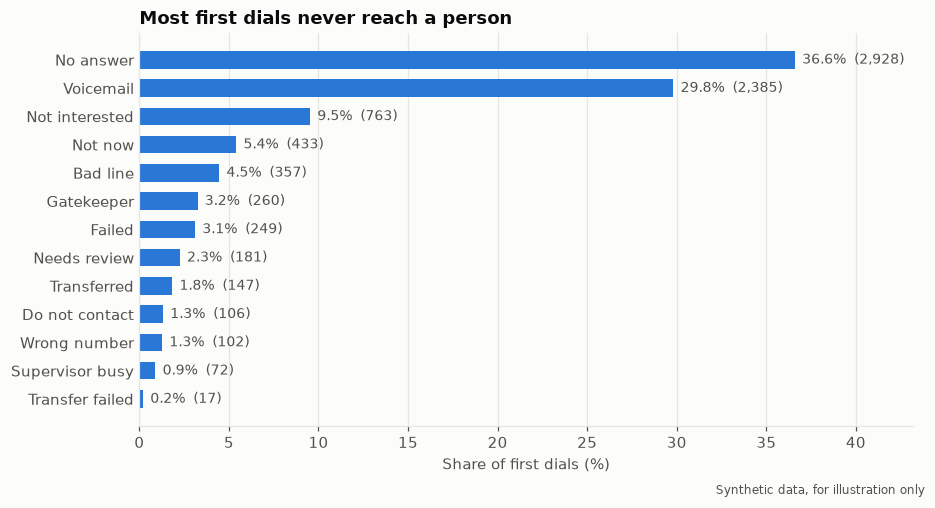

**Reading it (synthetic):**
- 74% of first dials end with nobody to talk to, so overall reach depends heavily on retries and call timing.
- `needs_review` (2.3%) is the size of the manual queue: calls where neither the AI's label nor a transcript rule decided.
- `do_not_contact` (1.3%) is rare, so it needs monitoring by count over time. A missed one is far more costly than the
  overall accuracy figure would show.

In [3]:
first = calls[calls.attempt == "first"]
LABELS = {"no_answer": "No answer", "voicemail": "Voicemail", "not_interested": "Not interested", "not_now": "Not now",
          "gatekeeper": "Gatekeeper", "needs_review": "Needs review", "transferred": "Transferred", "wrong_number": "Wrong number",
          "do_not_contact": "Do not contact", "transfer_declined": "Supervisor busy", "transfer_failed": "Transfer failed",
          "bad_line": "Bad line", "failed": "Failed"}
dist = first.outcome.value_counts().rename("calls").to_frame()
dist["share"] = dist.calls / dist.calls.sum()
plot = dist.sort_values("calls")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh([LABELS[i] for i in plot.index], plot.share * 100, color=BLUE, height=0.62)
for y, (_, r) in enumerate(plot.iterrows()):
    ax.text(r.share * 100 + 0.4, y, f"{r.share:.1%}  ({int(r.calls):,})", va="center", fontsize=9, color=MUTED)
ax.set_xlim(0, plot.share.max() * 118)
ax.set_xlabel("Share of first dials (%)")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.set_title("Most first dials never reach a person")
fig.tight_layout(rect=(0, 0.02, 1, 1))
note(fig)
plt.show()

unreached = dist.loc[["no_answer", "voicemail", "bad_line", "failed"], "share"].sum()
review = dist.loc["needs_review", "share"]
dnc = dist.loc["do_not_contact", "share"]
display(Markdown(f"""**Reading it (synthetic):**
- {unreached:.0%} of first dials end with nobody to talk to, so overall reach depends heavily on retries and call timing.
- `needs_review` ({review:.1%}) is the size of the manual queue: calls where neither the AI's label nor a transcript rule decided.
- `do_not_contact` ({dnc:.1%}) is rare, so it needs monitoring by count over time. A missed one is far more costly than the
  overall accuracy figure would show."""))


## 3. Contact rate by local hour and weekday

**Contact rate** = a person picked up ÷ first dials. Hours are in the *lead's* local time, using the time zone the app infers
(zip, then state, then area code), so errors in that inference would blur a real version of this chart.

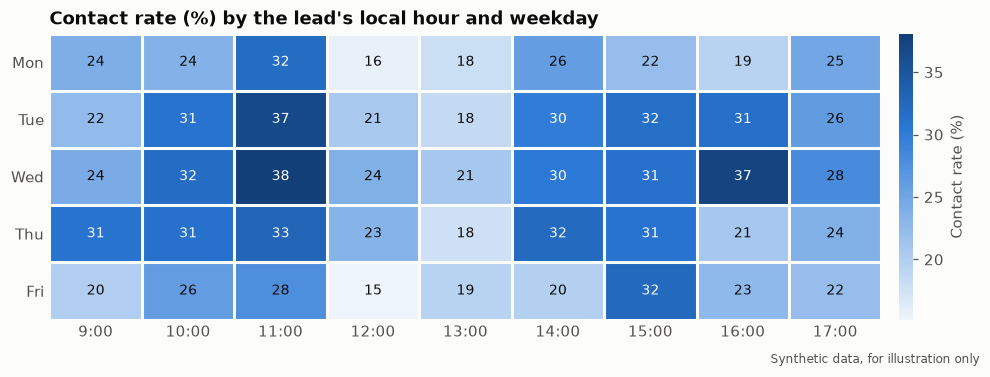

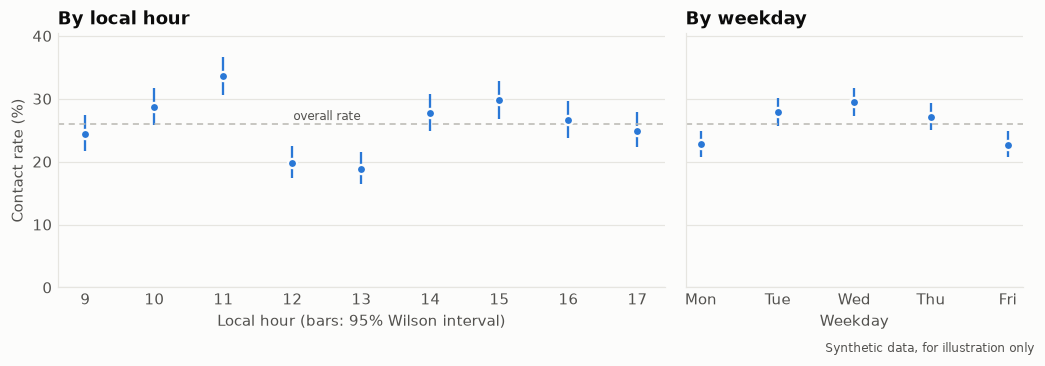

**Reading it (synthetic):**
- The best hour is 11:00 (33.6%) and the weakest is 13:00 (18.9%). Their 95% intervals
  don't overlap, so the gap is more than noise at this sample size.
- Each heatmap cell holds only about 177 calls, so differences of a few points between cells are mostly noise.
  Read the margins first, and the cells only for strong interactions.
- In real data this would be observational: if the dialer calls different leads at different hours, a gap here doesn't prove the hour
  caused it. Randomising call slots would be the clean test.

In [4]:
grid = first.pivot_table(index="weekday", columns="local_hour", values="picked_up", aggfunc="mean").loc[WEEKDAYS]
counts = first.pivot_table(index="weekday", columns="local_hour", values="picked_up", aggfunc="count").loc[WEEKDAYS]

fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(grid.values * 100, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", ["#eef4fb", "#8db8ea", BLUE, "#123f78"]), aspect="auto")
ax.set_xticks(range(len(HOURS)), [f"{h}:00" for h in HOURS])
ax.set_yticks(range(5), WEEKDAYS)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-.5, len(HOURS)), minor=True)
ax.set_yticks(np.arange(-.5, 5), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="minor", length=0)
mid = np.nanmean(grid.values) * 100
for i in range(5):
    for j in range(len(HOURS)):
        v = grid.values[i, j] * 100
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > mid + 3 else INK)
ax.set_title("Contact rate (%) by the lead's local hour and weekday")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="Contact rate (%)").outline.set_visible(False)
fig.tight_layout(rect=(0, 0.03, 1, 1))
note(fig)
plt.show()

by_hour = first.groupby("local_hour").picked_up.agg(["sum", "count"])
by_hour["rate"] = by_hour["sum"] / by_hour["count"]
by_hour["lo"], by_hour["hi"] = wilson(by_hour["sum"], by_hour["count"])
by_day = first.groupby("weekday").picked_up.agg(["sum", "count"]).loc[WEEKDAYS]
by_day["rate"] = by_day["sum"] / by_day["count"]
by_day["lo"], by_day["hi"] = wilson(by_day["sum"], by_day["count"])

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3), sharey=True, gridspec_kw={"width_ratios": [9, 5]})
for ax, d, xs, title in ((axes[0], by_hour, [f"{h}" for h in HOURS], "By local hour"), (axes[1], by_day, WEEKDAYS, "By weekday")):
    ax.errorbar(xs, d.rate * 100, yerr=[(d.rate - d.lo) * 100, (d.hi - d.rate) * 100], fmt="o", color=BLUE, ms=6,
                elinewidth=1.5, capsize=0, mec=SURFACE, mew=1.5)
    ax.axhline(first.picked_up.mean() * 100, color=NEUTRAL, lw=1, ls=(0, (4, 3)))
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.set_title(title)
    ax.tick_params(length=0)
axes[0].set_ylabel("Contact rate (%)")
axes[0].set_ylim(0, by_hour.hi.max() * 110)
axes[0].text(3.5, first.picked_up.mean() * 100 + 0.6, "overall rate", color=MUTED, fontsize=8, ha="center")
axes[0].set_xlabel("Local hour (bars: 95% Wilson interval)")
axes[1].set_xlabel("Weekday")
fig.tight_layout(rect=(0, 0.03, 1, 1))
note(fig)
plt.show()

best, worst = by_hour.rate.idxmax(), by_hour.rate.idxmin()
overlap = by_hour.lo[best] <= by_hour.hi[worst]
display(Markdown(f"""**Reading it (synthetic):**
- The best hour is {best}:00 ({by_hour.rate[best]:.1%}) and the weakest is {worst}:00 ({by_hour.rate[worst]:.1%}). Their 95% intervals
  {"overlap, so this sample can't separate them" if overlap else "don't overlap, so the gap is more than noise at this sample size"}.
- Each heatmap cell holds only about {int(counts.values.mean())} calls, so differences of a few points between cells are mostly noise.
  Read the margins first, and the cells only for strong interactions.
- In real data this would be observational: if the dialer calls different leads at different hours, a gap here doesn't prove the hour
  caused it. Randomising call slots would be the clean test."""))


### Check: does the analysis recover the known truth?

The data is synthetic, so we know the true pick-up rate for each hour. If the estimates didn't track it, the pipeline would be wrong.

In [5]:
true_rate = pd.Series({h: np.mean([p_pickup(h, d) for d in WEEKDAYS]) for h in HOURS}, name="true")
check = pd.DataFrame({"true": true_rate, "estimated": by_hour.rate, "lo": by_hour.lo, "hi": by_hour.hi})
check["true_in_95pct_ci"] = check["true"].between(check.lo, check.hi)
assert check.true_in_95pct_ci.mean() >= 7 / 9, "the estimates should usually cover the truth"
assert np.corrcoef(check["true"], check.estimated)[0, 1] > 0.8
print(f"Hours where the 95% interval covers the true rate: {check.true_in_95pct_ci.sum()} of {len(check)}")
print(f"Correlation between true and estimated rate: {np.corrcoef(check['true'], check.estimated)[0, 1]:.2f}")
check.round(3)


Hours where the 95% interval covers the true rate: 8 of 9
Correlation between true and estimated rate: 0.90


,true,estimated,lo,hi,true_in_95pct_ci
9,0.239,0.245,0.217,0.275,True
10,0.294,0.286,0.258,0.317,True
11,0.309,0.336,0.306,0.367,True
12,0.213,0.198,0.173,0.225,True
13,0.205,0.189,0.165,0.215,True
14,0.262,0.277,0.248,0.307,True
15,0.315,0.298,0.268,0.329,True
16,0.298,0.266,0.237,0.297,False
17,0.230,0.249,0.223,0.278,True


## 4. The funnel

Dialed → answered by a person → interested → transferred, per first dial. A separate step for leads who were offered a hand-off
isn't needed here, because the generator offers one to every interested lead.

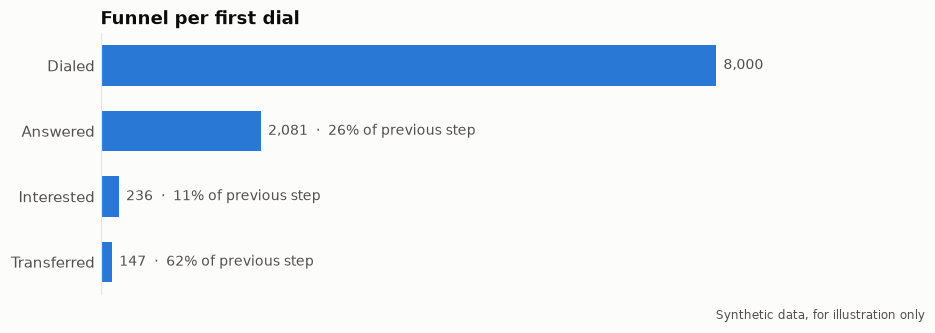

,stage,leads,pct_of_dialed,pct_of_previous
0,Dialed,8000,100.0%,
1,Answered,2081,26.0%,26.0%
2,Interested,236,2.9%,11.3%
3,Transferred,147,1.8%,62.3%


**Reading it (synthetic):**
- End to end, 1.8% of first dials become a live transfer, or about one in 54.
- The steepest drop is answered → interested (11%). That's the first place to look for
  improvement, though in practice that step depends on lead quality as much as on the agent.
- 38% of interested leads don't get a live transfer. Those are the warmest leads, so supervisor availability
  is a measurable loss, and each one needs a good callback.

In [6]:
answered = first.picked_up.sum()
interested = first.outcome.isin(INTERESTED).sum()
transferred = (first.outcome == "transferred").sum()
stages = pd.DataFrame({"stage": ["Dialed", "Answered", "Interested", "Transferred"], "leads": [len(first), answered, interested, transferred]})
stages["pct_of_dialed"] = stages.leads / len(first)
stages["pct_of_previous"] = stages.leads / stages.leads.shift(1)

fig, ax = plt.subplots(figsize=(8.5, 3.0))
y = np.arange(len(stages))[::-1]
ax.barh(y, stages.leads, color=BLUE, height=0.62)
ax.set_yticks(y, stages.stage)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, len(first) * 1.32)
for yi, r in zip(y, stages.itertuples()):
    step = "" if pd.isna(r.pct_of_previous) else f"  ·  {r.pct_of_previous:.0%} of previous step"
    ax.text(r.leads + len(first) * 0.012, yi, f"{r.leads:,}{step}", va="center", fontsize=9, color=MUTED)
ax.spines["bottom"].set_visible(False)
ax.xaxis.set_visible(False)
ax.set_title("Funnel per first dial")
fig.tight_layout(rect=(0, 0.04, 1, 1))
note(fig)
plt.show()

steps = stages.pct_of_previous.dropna()
display(stages.assign(pct_of_dialed=stages.pct_of_dialed.map("{:.1%}".format), pct_of_previous=stages.pct_of_previous.map(lambda v: "" if pd.isna(v) else f"{v:.1%}")))
display(Markdown(f"""**Reading it (synthetic):**
- End to end, {transferred / len(first):.1%} of first dials become a live transfer, or about one in {len(first) / transferred:.0f}.
- The steepest drop is {stages.stage[steps.idxmin() - 1].lower()} → {stages.stage[steps.idxmin()].lower()} ({steps.min():.0%}). That's the first place to look for
  improvement, though in practice that step depends on lead quality as much as on the agent.
- {1 - transferred / interested:.0%} of interested leads don't get a live transfer. Those are the warmest leads, so supervisor availability
  is a measurable loss, and each one needs a good callback."""))


## 5. Callback timing

How far ahead are callbacks scheduled, and does the delay change whether the lead picks up? The comparison splits by who set the
time, since a lead who named a time made a small commitment.

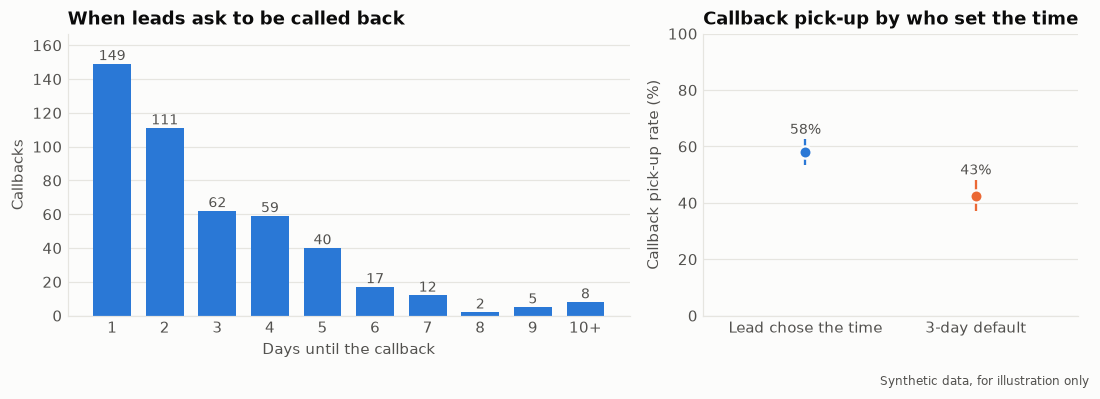

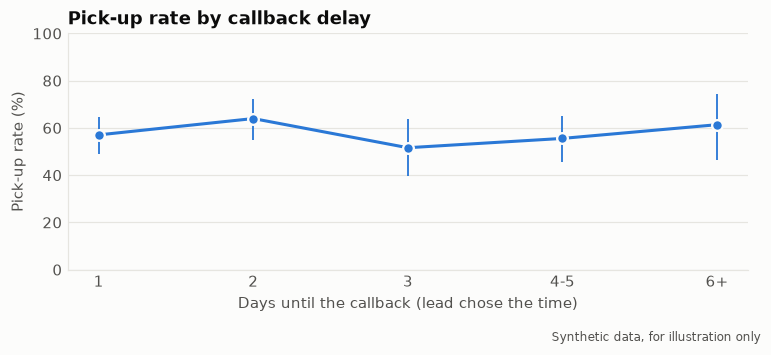

**Reading it (synthetic):**
- 69% of leads who name a time choose within 3 days, so the 3-day default isn't far from what people ask for.
- Pick-up is 15 points higher when the lead chose the time. In real data this wouldn't show that asking *causes* pick-up, because
  people who name a time may simply be more interested. A randomised test would be needed to measure the effect of asking.
- The generator builds in a small fall in pick-up per day of delay, but this sample can't detect it: next-day callbacks pick up at
  57% and 6+ day callbacks at 61% (n=44), with overlapping intervals. So a flat-looking chart here is *not* evidence of no
  effect. A real analysis would need a power estimate first, then a logistic model controlling for hour and lead source.

In [7]:
# Equal one-day bins for the histogram (wider bins would look tall just for being wide); wider bins only for rates.
BINS = [0, 1, 2, 3, 5, 22]
BIN_LABELS = ["1", "2", "3", "4-5", "6+"]
cb["lag_bin"] = pd.cut(cb.lag_days, BINS, labels=BIN_LABELS)
SERIES = {"Lead chose the time": BLUE, "3-day default": ORANGE}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [6, 4]})
ax = axes[0]
chose = cb[cb.time_source == "Lead chose the time"]
lag_counts = chose.lag_days.clip(upper=10).value_counts().reindex(range(1, 11), fill_value=0)
day_labels = [str(d) for d in range(1, 10)] + ["10+"]
ax.bar(day_labels, lag_counts, color=BLUE, width=0.72)
for x, v in enumerate(lag_counts):
    ax.text(x, v + lag_counts.max() * 0.015, f"{v:,}", ha="center", fontsize=9, color=MUTED)
ax.set_ylim(0, lag_counts.max() * 1.12)
ax.set_xlabel("Days until the callback")
ax.set_ylabel("Callbacks")
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_title("When leads ask to be called back")

ax = axes[1]
pick = cb.groupby("time_source").picked_up.agg(["sum", "count"]).loc[list(SERIES)]
pick["rate"] = pick["sum"] / pick["count"]
pick["lo"], pick["hi"] = wilson(pick["sum"], pick["count"])
for i, (name, r) in enumerate(pick.iterrows()):
    ax.errorbar([i], [r.rate * 100], yerr=[[(r.rate - r.lo) * 100], [(r.hi - r.rate) * 100]], fmt="o", color=SERIES[name], ms=8,
                elinewidth=1.5, mec=SURFACE, mew=1.5)
    ax.text(i, r.hi * 100 + 2, f"{r.rate:.0%}", ha="center", fontsize=9, color=MUTED)
ax.set_xticks([0, 1], list(SERIES))
ax.set_xlim(-0.6, 1.6)
ax.set_ylim(0, 100)
ax.set_ylabel("Callback pick-up rate (%)")
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_title("Callback pick-up by who set the time")
fig.tight_layout(rect=(0, 0.04, 1, 1))
note(fig)
plt.show()

by_lag = chose.groupby("lag_bin", observed=True).picked_up.agg(["sum", "count"]).reindex(BIN_LABELS)
by_lag["rate"] = by_lag["sum"] / by_lag["count"]
by_lag["lo"], by_lag["hi"] = wilson(by_lag["sum"], by_lag["count"])

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.errorbar(BIN_LABELS, by_lag.rate * 100, yerr=[(by_lag.rate - by_lag.lo) * 100, (by_lag.hi - by_lag.rate) * 100], fmt="o-", color=BLUE, lw=2, ms=7,
            elinewidth=1.2, mec=SURFACE, mew=1.5)
ax.set_ylim(0, 100)
ax.set_xlabel("Days until the callback (lead chose the time)")
ax.set_ylabel("Pick-up rate (%)")
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_title("Pick-up rate by callback delay")
fig.tight_layout(rect=(0, 0.05, 1, 1))
note(fig)
plt.show()

gap = pick.rate["Lead chose the time"] - pick.rate["3-day default"]
within = (chose.lag_days <= 3).mean()
early, late = by_lag.loc["1"], by_lag.loc["6+"]
overlap_lag = early.lo <= late.hi
display(Markdown(f"""**Reading it (synthetic):**
- {within:.0%} of leads who name a time choose within 3 days, so the 3-day default isn't far from what people ask for.
- Pick-up is {gap * 100:.0f} points higher when the lead chose the time. In real data this wouldn't show that asking *causes* pick-up, because
  people who name a time may simply be more interested. A randomised test would be needed to measure the effect of asking.
- The generator builds in a small fall in pick-up per day of delay, but this sample {"can't detect it" if overlap_lag else "only just shows it"}: next-day callbacks pick up at
  {early.rate:.0%} and 6+ day callbacks at {late.rate:.0%} (n={int(late["count"])}), with {"overlapping" if overlap_lag else "separate"} intervals. So a flat-looking chart here is *not* evidence of no
  effect. A real analysis would need a power estimate first, then a logistic model controlling for hour and lead source."""))


## What would change with real data

- **Replace section 1** with a query on the `Call` table, keeping the column names. Sections 2-5 then run unchanged.
- **Label a validation set.** Hand-label a sample of transcripts so the AI labels and transcript rules can be scored per class
  (precision, recall, and agreement via Cohen's κ), with `do_not_contact` recall as the key safety metric. No such evaluation
  exists yet.
- **Randomise call slots and "ask for a time"** before reading hour or callback effects as causal.
- **Add lead-source and time-zone-source controls:** area-code zones are less reliable than zip codes, which can blur the hour effect.